**EXP-03 IMPLEMENTATION OF CONVOLUTIONAL NEURAL NETWORKS (CNNs) FOR IMAGE CLASSIFICATION**

**24BAD130 Vishal S**

**PART A: DATASET PREPARATION**

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import cifar10

In [2]:
# Load CIFAR-10 dataset

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1525s 9us/step
Training data: (50000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)


In [3]:
# Normalize pixel values from 0-255 to 0-1

x_train = x_train / 255.0
x_test = x_test / 255.0

print("Normalization completed")

Normalization completed


In [4]:
# Take 5000 images from training data for validation

x_val = x_train[-5000:]
y_val = y_train[-5000:]

# Keep remaining 45000 images for training

x_train = x_train[:-5000]
y_train = y_train[:-5000]

print("Training images:", x_train.shape)
print("Validation images:", x_val.shape)
print("Testing images:", x_test.shape)

Training images: (45000, 32, 32, 3)
Validation images: (5000, 32, 32, 3)
Testing images: (10000, 32, 32, 3)


**PART B: CNN MODEL IMPLEMENTATION**

In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

In [6]:
model = Sequential()

# Convolution layer 1
model.add(Conv2D(32, (3, 3), activation="relu",
                 input_shape=(32, 32, 3)))
# Max pooling layer 1
model.add(MaxPooling2D((2, 2)))
# Convolution layer 2
model.add(Conv2D(64, (3, 3), activation="relu"))
# Max pooling layer 2
model.add(MaxPooling2D((2, 2)))
# Convert feature maps into one-dimensional vector
model.add(Flatten())
# Fully connected layer
model.add(Dense(128, activation="relu"))
# Output layer
model.add(Dense(10, activation="softmax"))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully")

Model compiled successfully


**PART C: MODEL TRAINING AND EVALUATION**

In [9]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    validation_data=(x_val, y_val)
)

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 67s 47ms/step - accuracy: 0.4778 - loss: 1.4500 - val_accuracy: 0.5850 - val_loss: 1.1941
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 62s 44ms/step - accuracy: 0.6114 - loss: 1.1052 - val_accuracy: 0.6522 - val_loss: 1.0080
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 63s 45ms/step - accuracy: 0.6627 - loss: 0.9715 - val_accuracy: 0.6778 - val_loss: 0.9462
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 61s 44ms/step - accuracy: 0.6928 - loss: 0.8811 - val_accuracy: 0.6888 - val_loss: 0.8967
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 63s 44ms/step - accuracy: 0.7222 - loss: 0.7994 - val_accuracy: 0.7008 - val_loss: 0.8776
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 80s 43ms/step - accuracy: 0.7449 - loss: 0.7322 - val_accuracy: 0.7076 - val_loss: 0.8904
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 82s 44ms/step - accuracy: 0.7639 - loss: 0.6735 - val_accuracy: 0.6986 - val_loss: 0.9438
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 82s 43ms/step - accuracy: 0.7853 -

In [10]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test
)

print("Testing Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.6905 - loss: 0.9886
Testing Accuracy: 0.690500020980835


In [11]:
print("Training Accuracy:",
      history.history["accuracy"][-1])

print("Validation Accuracy:",
      history.history["val_accuracy"][-1])

print("Training Loss:",
      history.history["loss"][-1])

print("Validation Loss:",
      history.history["val_loss"][-1])

print("Testing Accuracy:",
      test_accuracy)

Training Accuracy: 0.822088897228241
Validation Accuracy: 0.704200029373169
Training Loss: 0.5062804222106934
Validation Loss: 0.9567880034446716
Testing Accuracy: 0.690500020980835


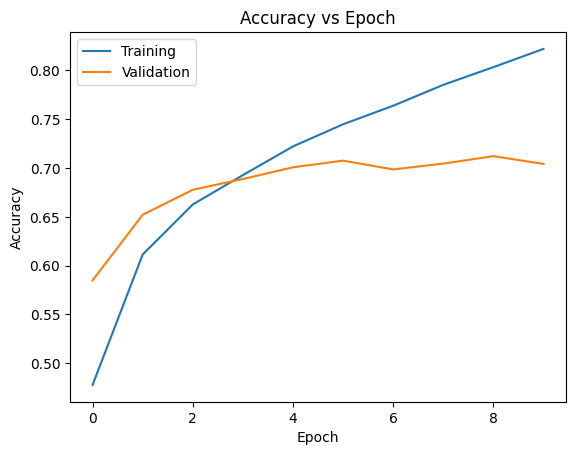

In [12]:
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

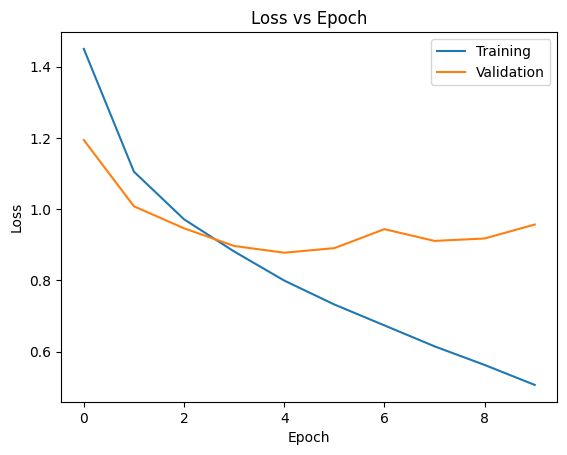

In [13]:
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")

plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.show()

**PART D: PERFORMANCE ANALYSIS**

In [14]:
from sklearn.metrics import accuracy_score

# Predict test images
prediction = model.predict(x_test)
# Convert probabilities to class numbers
predicted_classes = np.argmax(prediction, axis=1)
# Convert actual labels into 1D
actual_classes = y_test.flatten()
# Calculate accuracy
accuracy = accuracy_score(
    actual_classes,
    predicted_classes
)

print("Classification Accuracy:",
      accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step
Classification Accuracy: 69.05 %


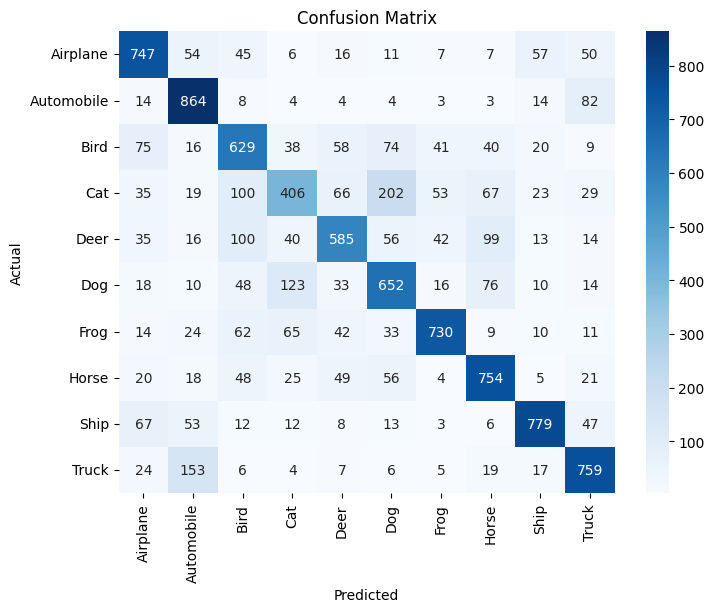

In [16]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# CIFAR-10 class names
classes = [
    "Airplane",
    "Automobile",
    "Bird",
    "Cat",
    "Deer",
    "Dog",
    "Frog",
    "Horse",
    "Ship",
    "Truck"
]

# Create confusion matrix
cm = confusion_matrix(
    actual_classes,
    predicted_classes
)

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

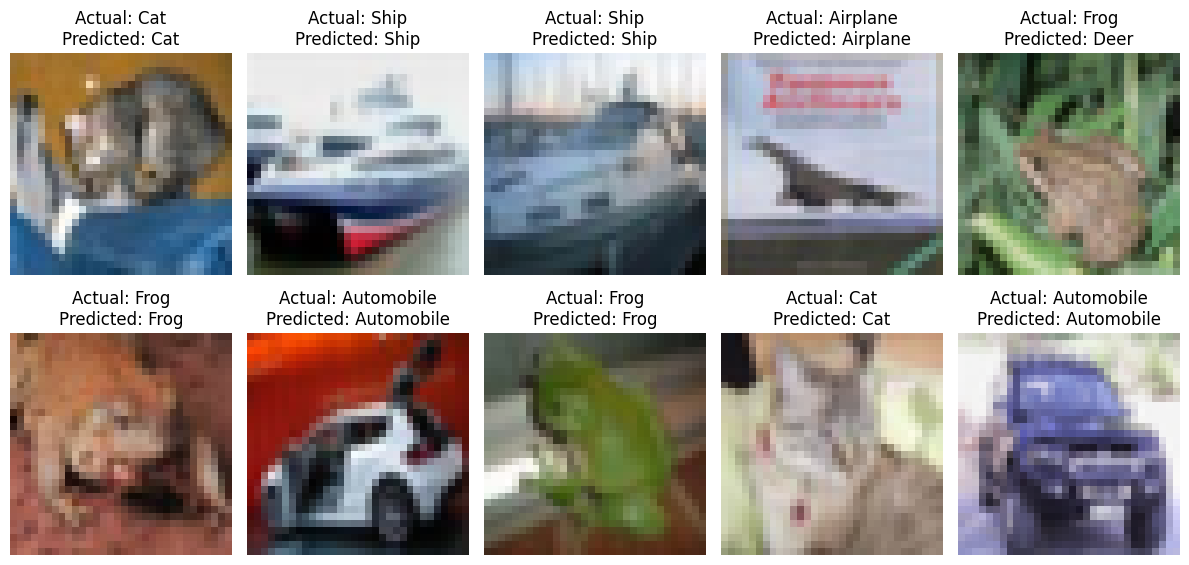

In [17]:
plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i])

    actual = classes[actual_classes[i]]
    predicted = classes[predicted_classes[i]]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:
misclassified = np.where(
    predicted_classes != actual_classes
)[0]

print("Number of Misclassified Images:",
      len(misclassified))

Number of Misclassified Images: 3095


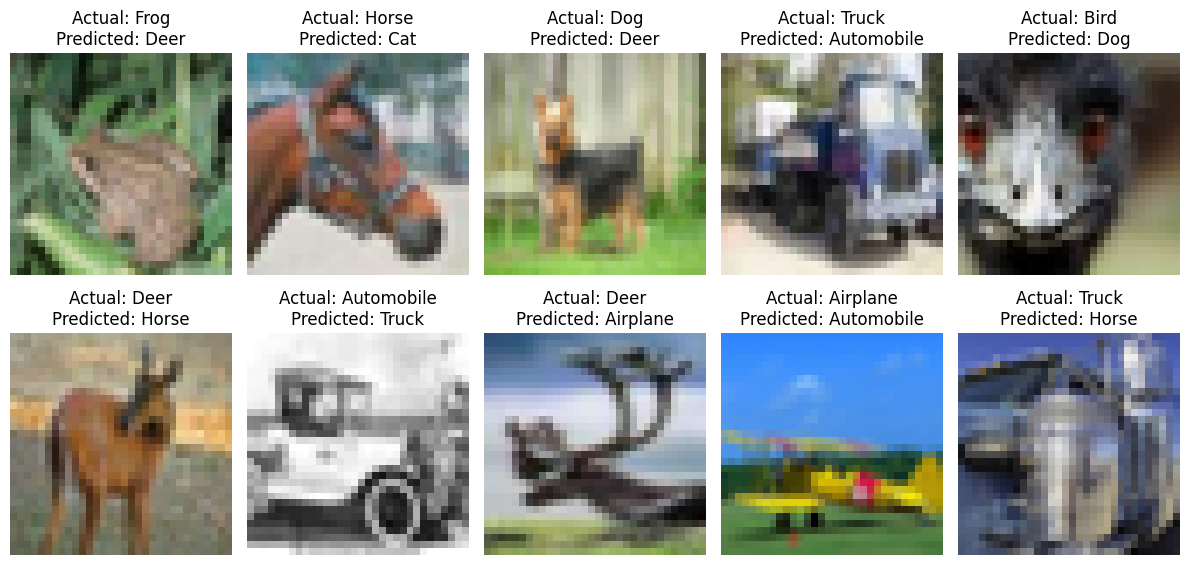

In [19]:
plt.figure(figsize=(12, 6))

for i in range(10):

    index = misclassified[i]

    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[index])

    actual = classes[actual_classes[index]]
    predicted = classes[predicted_classes[index]]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()